In [1]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.15.0+cu132
CUDA available: True


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

In [3]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

69.6%
100.0%


In [4]:
generator = torch.Generator().manual_seed(42)

train_size = 45000
val_size = 5000

train_split, val_split = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

In [5]:
batch_size = 64

train_loader = DataLoader(
    train_split,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_split,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [7]:
images, labels = next(iter(train_loader))

print("Training images:", len(train_split))
print("Validation images:", len(val_split))
print("Testing images:", len(test_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum label:", labels.min().item())
print("Maximum label:", labels.max().item())

Training images: 45000
Validation images: 5000
Testing images: 10000
Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Minimum label: 0
Maximum label: 9


In [8]:
import torch.nn as nn
import torch.optim as optim

In [9]:
class MLP(nn.Module):

    def __init__(self):
        super(MLP, self).__init__()

        self.network = nn.Sequential(

            # First layer: 3072 inputs -> 512 neurons
            nn.Linear(3072, 512),
            nn.ReLU(),

            # Second layer: 512 -> 256 neurons
            nn.Linear(512, 256),
            nn.ReLU(),

            # Third layer: 256 -> 10 output classes
            nn.Linear(256, 10)
        )

    def forward(self, x):

        # Flatten images into 3072 numbers
        x = torch.flatten(x, start_dim=1)

        # Pass data through the network
        x = self.network(x)

        return x

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MLP().to(device)

print(model)
print("Using device:", device)

MLP(
  (network): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Using device: cuda


In [19]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [20]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move images and labels to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Clear old gradients
        optimizer.zero_grad()

        # Backward pass
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate training loss
        running_loss += loss.item() * images.size(0)

        # Calculate accuracy
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [22]:
def evaluate(model, data_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            # Move data to GPU
            images = images.to(device)
            labels = labels.to(device)

            # Make predictions
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            # Find predicted classes
            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [23]:
# Number of training epochs
num_epochs = 10

# Store results for plotting
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "train_accuracy": [],
    "test_accuracy": []
}

for epoch in range(num_epochs):

    # Train the model
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Evaluate on validation dataset
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    # Evaluate on test dataset
    test_loss, test_accuracy = evaluate(
        model, test_loader, criterion, device
    )

    # Save results
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["train_accuracy"].append(train_accuracy)
    history["test_accuracy"].append(test_accuracy)

    # Display results
    print(f"\nEpoch [{epoch+1}/{num_epochs}]")

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")

    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Test Accuracy: {test_accuracy:.2f}%")


Epoch [1/10]
Training Loss: 1.6687
Validation Loss: 1.5588
Training Accuracy: 40.79%
Test Accuracy: 44.99%

Epoch [2/10]
Training Loss: 1.4744
Validation Loss: 1.4804
Training Accuracy: 47.76%
Test Accuracy: 49.00%

Epoch [3/10]
Training Loss: 1.3762
Validation Loss: 1.4318
Training Accuracy: 51.23%
Test Accuracy: 50.11%

Epoch [4/10]
Training Loss: 1.2858
Validation Loss: 1.4120
Training Accuracy: 54.49%
Test Accuracy: 50.94%

Epoch [5/10]
Training Loss: 1.2144
Validation Loss: 1.4712
Training Accuracy: 57.08%
Test Accuracy: 50.52%

Epoch [6/10]
Training Loss: 1.1429
Validation Loss: 1.4554
Training Accuracy: 59.36%
Test Accuracy: 50.31%

Epoch [7/10]
Training Loss: 1.0825
Validation Loss: 1.4476
Training Accuracy: 61.85%
Test Accuracy: 50.93%

Epoch [8/10]
Training Loss: 1.0234
Validation Loss: 1.4857
Training Accuracy: 63.76%
Test Accuracy: 51.80%

Epoch [9/10]
Training Loss: 0.9598
Validation Loss: 1.5054
Training Accuracy: 65.87%
Test Accuracy: 52.29%

Epoch [10/10]
Training Loss

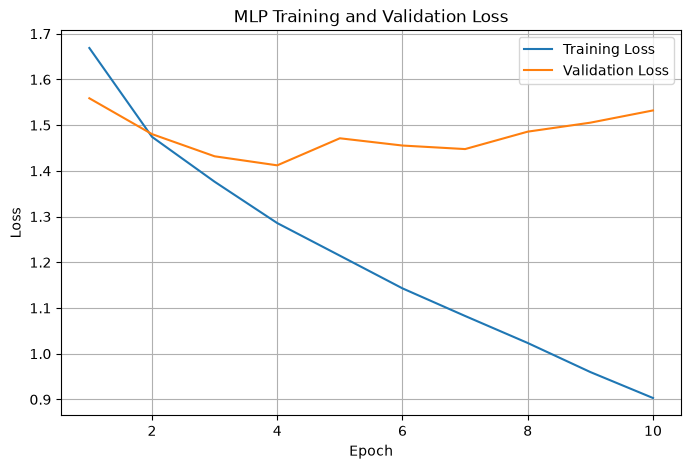

In [24]:
import matplotlib.pyplot as plt
import os

# Create outputs folder if it doesn't exist
os.makedirs("outputs", exist_ok=True)

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig("outputs/mlp_loss.png", dpi=300, bbox_inches="tight")

plt.show()

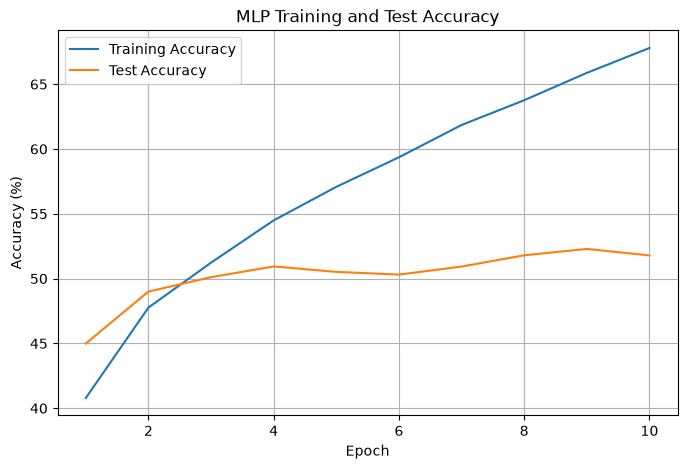

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["test_accuracy"],
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MLP Training and Test Accuracy")

plt.legend()
plt.grid(True)

plt.savefig("outputs/mlp_accuracy.png", dpi=300, bbox_inches="tight")

plt.show()

In [27]:
print("FINAL MLP RESULTS")
print("-------------------------")

print(f"Training Loss: {history['train_loss'][-1]:.4f}")
print(f"Validation Loss: {history['val_loss'][-1]:.4f}")
print(f"Validation Accuracy: {history['val_accuracy'][-1]:.2f}%")

print(f"Training Accuracy: {history['train_accuracy'][-1]:.2f}%")
print(f"Test Accuracy: {history['test_accuracy'][-1]:.2f}%")

FINAL MLP RESULTS
-------------------------
Training Loss: 0.9031
Validation Loss: 1.5321
Validation Accuracy: 52.00%
Training Accuracy: 67.79%
Test Accuracy: 51.79%


In [31]:
import csv

with open("outputs/mlp_results.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Epoch",
        "Training Loss",
        "Validation Loss",
        "Training Accuracy",
        "Validation Accuracy",
        "Test Accuracy"
    ])

    for i in range(num_epochs):
        writer.writerow([
            i + 1,
            history["train_loss"][i],
            history["val_loss"][i],
            history["train_accuracy"][i],
            history["val_accuracy"][i],
            history["test_accuracy"][i]
        ])

print("Results saved successfully!")

Results saved successfully!


## Exercise 1 – MLP Classifier: Results and Discussion

The MLP classifier was implemented using three fully connected Linear layers with ReLU activation functions. The network takes flattened CIFAR-10 images containing 3,072 input features and produces 10 output classes.

CrossEntropyLoss was used as the loss function, while the Adam optimizer was selected with a learning rate of 0.001.

The model achieved a training accuracy of 67.79% and a validation accuracy of 52%, resulting in a generalisation gap of 15.79 percentage points.

The increasing validation loss suggests that the model may be overfitting. This indicates that the model performs better on training data than on unseen validation data.

The results demonstrate some limitations of using a fully connected neural network for image classification. Since flattening removes the spatial structure of images, an MLP may struggle to capture important visual patterns.

Further improvements through regularisation techniques and convolutional neural networks will be investigated in the following exercises.